# Plotting Pandas

Pandas has built-in capabilities for data visualization! It's built-off of matplotlib, but it baked into pandas for easier usage!  

Let's take a look!


In [1]:
import pandas as pd
import numpy as np
#matplotlib inline

## Plotting Series

Series can be plotted using plot() method. Uses index as X-axis. Specify if you want a different index.

<Axes: >

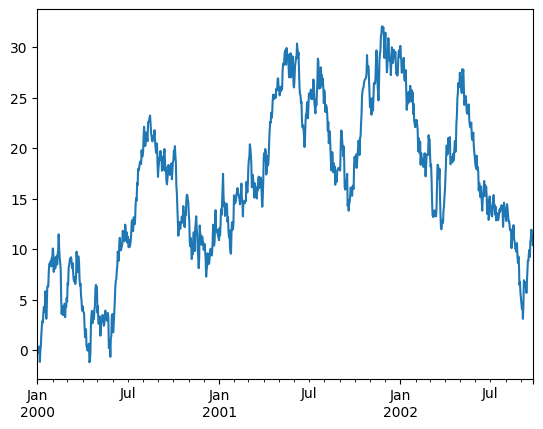

In [2]:
# Create a Series and plot it
ts = pd.Series(np.random.randn(1000), index=pd.date_range('1/1/2000', periods=1000))
ts = ts.cumsum()
ts.plot()

<Axes: >

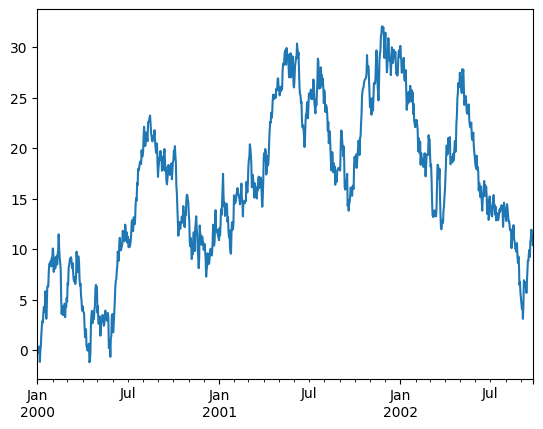

In [3]:
ts.plot(kind='line')

<Axes: >

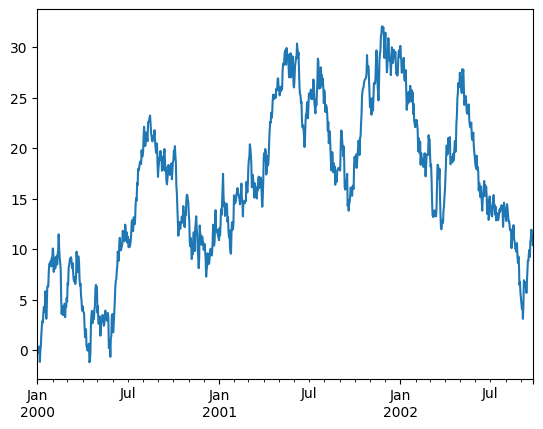

In [4]:
ts.plot.line()

<Axes: >

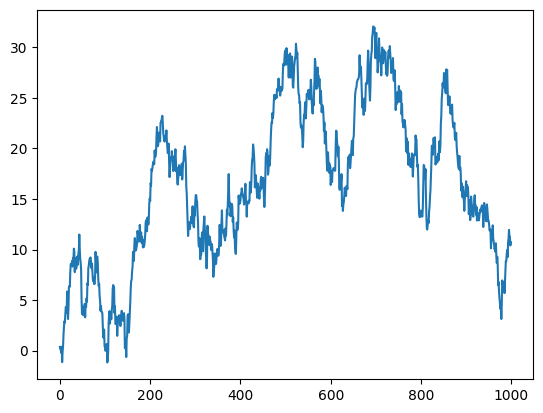

In [5]:
ts.plot.line(use_index=False)

## Plotting DataFrames

Each column of the dataframe is plotted separately on the same plot using index as X-axis.  

Again plot kind can be specified and plots like bar plots can group together columns!


In [6]:
#Dataframes has direct access to the plot function. This is a very useful feature combining matplotlib to Pandas

speed = [0.1, 17.5, 40, 48, 52, 69, 88]
lifespan = [2, 8, 70, 1.5, 25, 12, 28]
index = ['snail', 'pig', 'elephant', 'rabbit', 'giraffe', 'coyote', 'horse']
df = pd.DataFrame({'speed': speed, 'lifespan': lifespan}, index=index)
print(df)


          speed  lifespan
snail       0.1       2.0
pig        17.5       8.0
elephant   40.0      70.0
rabbit     48.0       1.5
giraffe    52.0      25.0
coyote     69.0      12.0
horse      88.0      28.0


<Axes: >

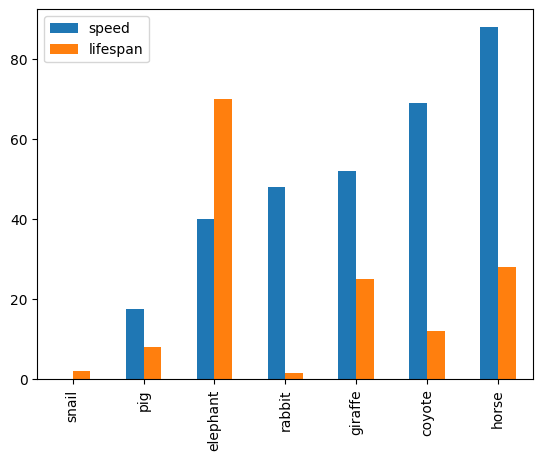

In [7]:
#plot using plot with bar method
df.plot.bar()

<Axes: >

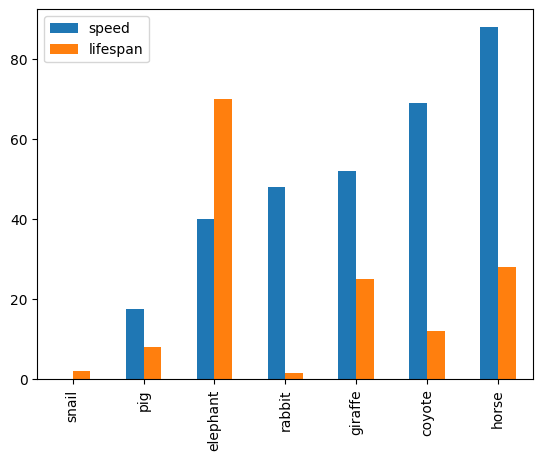

In [8]:
# Same plot with plot with kind as bar
df.plot(kind='bar')

<Axes: >

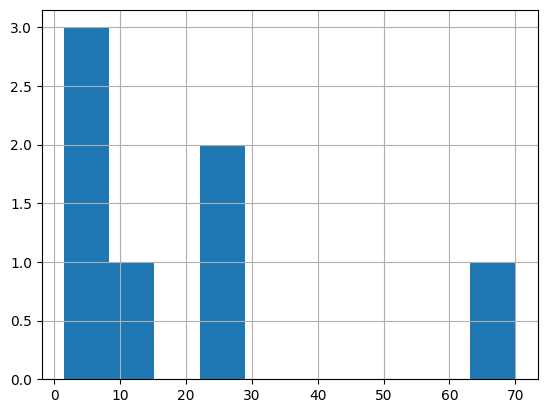

In [9]:
#Find the distribution of a column - plotting series!
df['lifespan'].hist()

<Axes: >

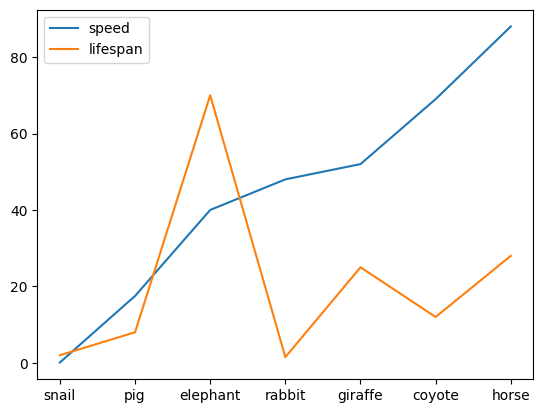

In [10]:
#plot using line
df.plot.line()

## The Data

The following code synthesizes two new dataframes for experimenting with different types of plots.

In [21]:
# Daily index: 2000-01-01 to 2002-09-26 (1000 rows)
index = pd.date_range("2000-01-01", periods=1000, freq="D")

# Standard normal values (mean 0, std 1), independent columns.
# Remove the seed line if you want different values on every run.
rng = np.random.default_rng(42)

df1 = pd.DataFrame(
    rng.standard_normal((1000, 4)),
    index=index,
    columns=["A", "B", "C", "D"],
)

# Uniform random values in [0, 1), 10 rows x 4 columns, default 0-9 integer index.
# Remove the seed line if you want different values on every run.
rng = np.random.default_rng(42)

df2 = pd.DataFrame(
    rng.random((10, 4)),
    columns=["a", "b", "c", "d"],
)

## Style Sheets

Matplotlib has [style sheets](http://matplotlib.org/gallery.html#style_sheets) you can use to make your plots look a little nicer. These style sheets include plot_bmh,plot_fivethirtyeight,plot_ggplot and more. They basically create a set of style rules that your plots follow. I recommend using them, they make all your plots have the same look and feel more professional. You can even create your own if you want your company's plots to all have the same look (it is a bit tedious to create on though).

Here is how to use them.

**Before plt.style.use() your plots look like this:**

<Axes: >

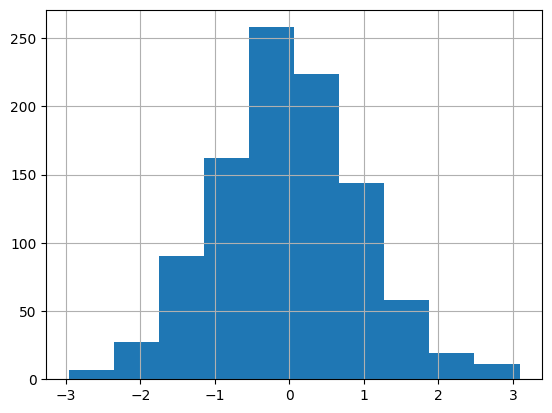

In [14]:
df1['A'].hist()

Call the style:

In [22]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

Now your plots look like this:

<Axes: >

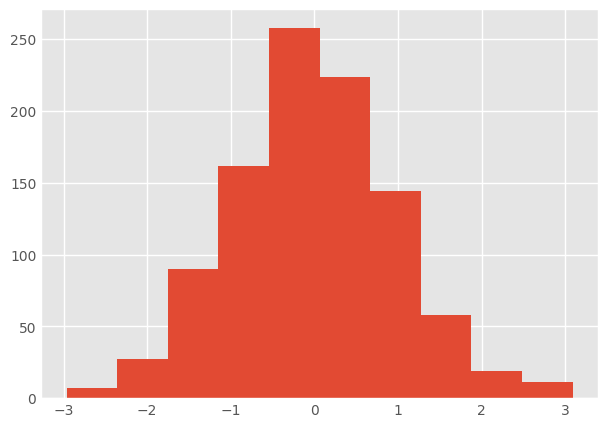

In [23]:
df1['A'].hist()

<Axes: >

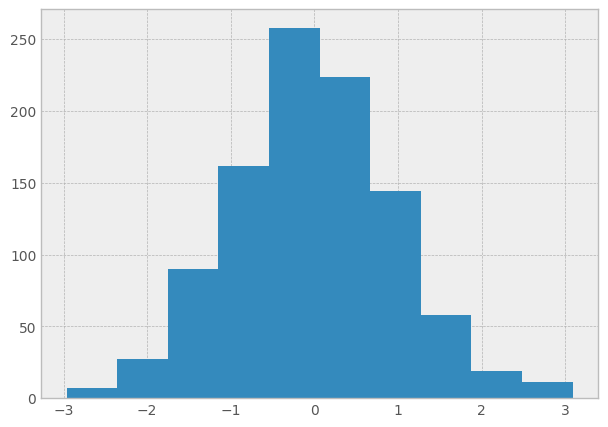

In [24]:
plt.style.use('bmh')
df1['A'].hist()

<Axes: >

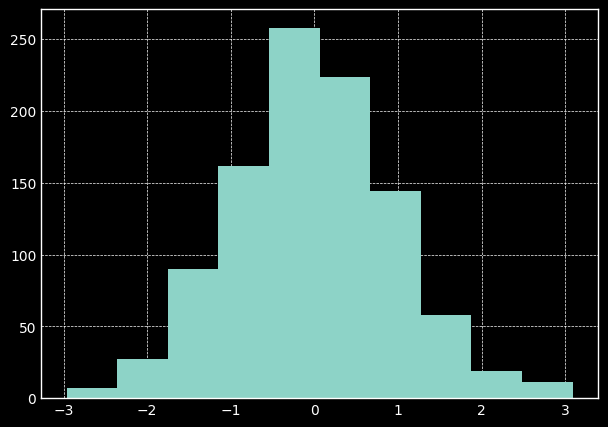

In [25]:
plt.style.use('dark_background')
df1['A'].hist()

<Axes: >

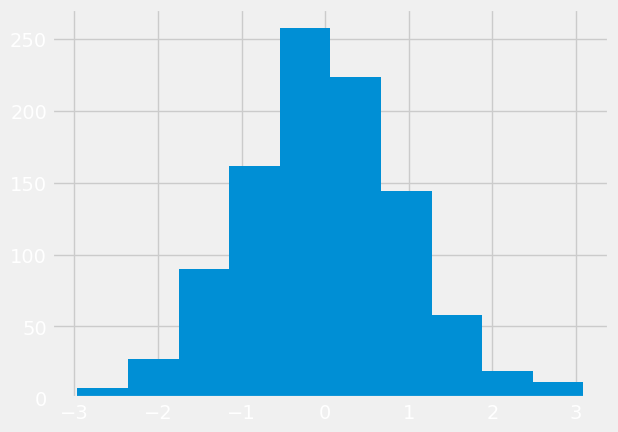

In [26]:
plt.style.use('fivethirtyeight')
df1['A'].hist()

In [27]:
plt.style.use('ggplot')

Let's stick with the ggplot style and actually show you how to utilize pandas built-in plotting capabilities!

# Plot Types

There are several plot types built-in to pandas, most of them statistical plots by nature:

* df.plot.area     
* df.plot.barh     
* df.plot.density  
* df.plot.hist     
* df.plot.line     
* df.plot.scatter
* df.plot.bar      
* df.plot.box      
* df.plot.hexbin   
* df.plot.kde      
* df.plot.pie

You can also just call df.plot(kind='hist') or replace that kind argument with any of the key terms shown in the list above (e.g. 'box','barh', etc..)
___

Let's start going through them!

## Area

<Axes: >

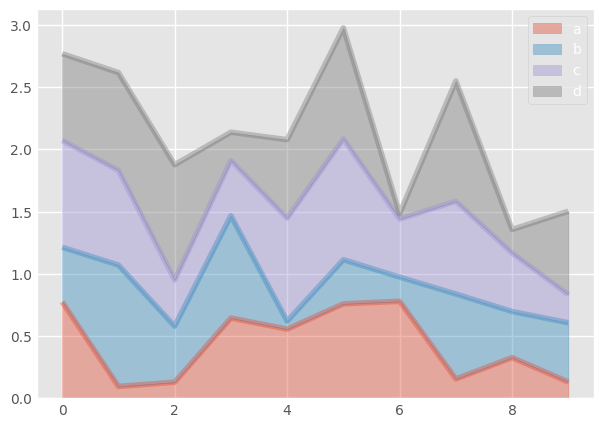

In [28]:
df2.plot.area(alpha=0.4)

## Barplots

In [29]:
df2.head()

,a,b,c,d
0,0.773956,0.438878,0.858598,0.697368
1,0.094177,0.975622,0.761140,0.786064
2,0.128114,0.450386,0.370798,0.926765
3,0.643865,0.822762,0.443414,0.227239
4,0.554585,0.063817,0.827631,0.631664


<Axes: >

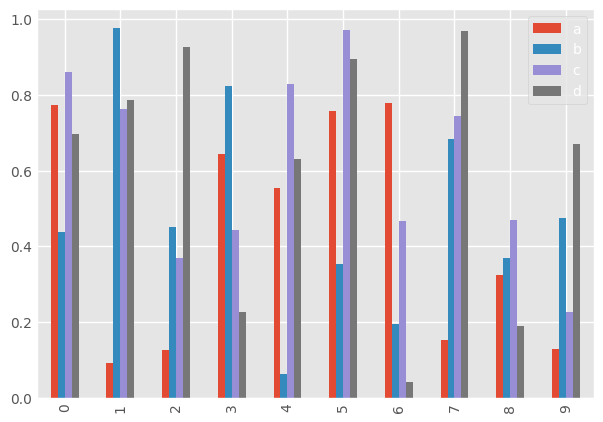

In [30]:
df2.plot.bar()

<Axes: >

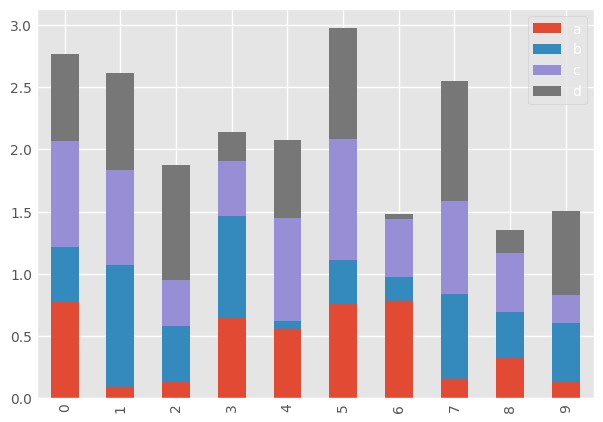

In [31]:
df2.plot.bar(stacked=True)

## Histograms

<Axes: ylabel='Frequency'>

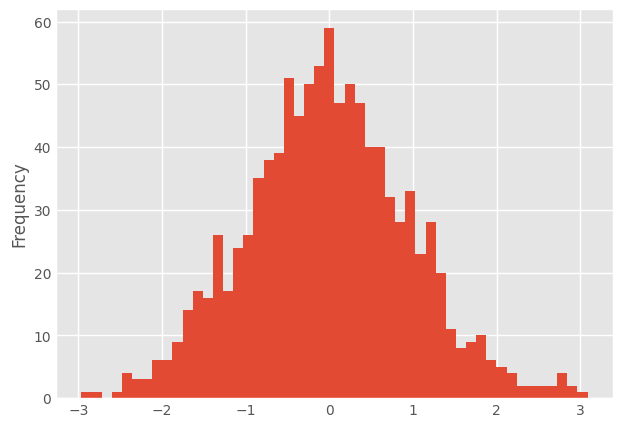

In [32]:
df1['A'].plot.hist(bins=50)

## Line Plots

<Axes: >

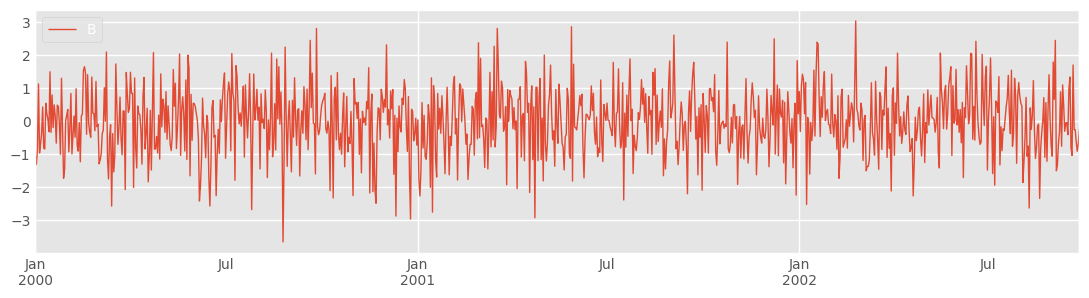

In [33]:
df1.plot.line(y='B',figsize=(12,3),lw=1)

## Scatter Plots

<Axes: xlabel='A', ylabel='B'>

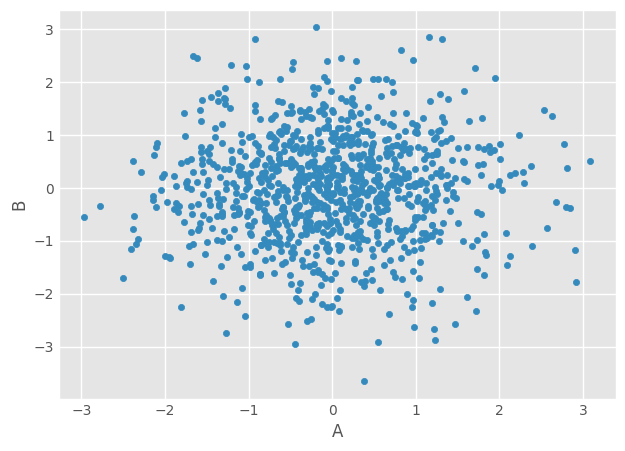

In [34]:
df1.plot.scatter(x='A',y='B')

You can use c to color based off another column value
Use cmap to indicate colormap to use.
For all the colormaps, check out: http://matplotlib.org/users/colormaps.html

<Axes: xlabel='A', ylabel='B'>

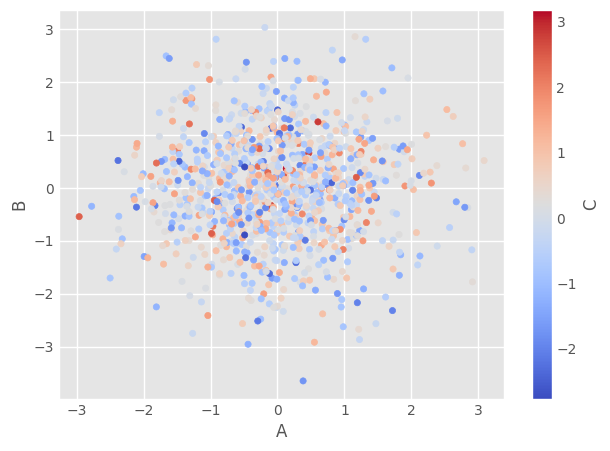

In [35]:
df1.plot.scatter(x='A',y='B',c='C',cmap='coolwarm')

## BoxPlots

<Axes: >

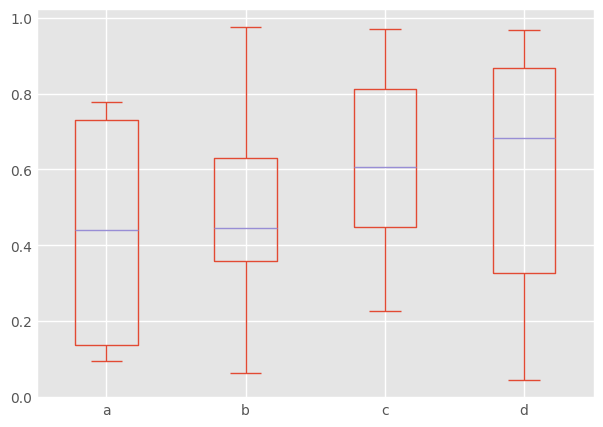

In [36]:
df2.plot.box() # Can also pass a by= argument for groupby

## Hexagonal Bin Plot

Useful for Bivariate Data, alternative to scatterplot:

<Axes: xlabel='a', ylabel='b'>

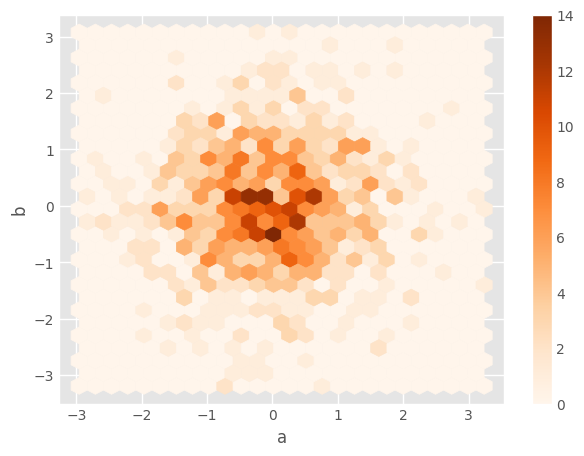

In [37]:
df = pd.DataFrame(np.random.randn(1000, 2), columns=['a', 'b'])
df.plot.hexbin(x='a',y='b',gridsize=25,cmap='Oranges')

This method of plotting will be a lot easier to use than full-on matplotlib, it balances ease of use with control over the figure. A lot of the plot calls also accept additional arguments of their parent matplotlib plt. call.



## Sample data Analysis

A small fake data set of the personal information of a few individuals in US.
Some samples are shown. Try more as recommended in the blank code cells.

In [38]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
df = pd.DataFrame({
    'name':['john','mary','peter','jeff','bill','lisa','jose'],
    'age':[23,78,22,19,45,33,20],
    'gender':['M','F','M','M','M','F','M'],
    'state':['california','dc','california','dc','california','texas','texas'],
    'num_children':[2,0,0,3,2,1,4],
    'num_pets':[5,1,0,5,2,2,3]
})
df

,name,age,gender,state,num_children,num_pets
0,john,23,M,california,2,5
1,mary,78,F,dc,0,1
2,peter,22,M,california,0,0
3,jeff,19,M,dc,3,5
4,bill,45,M,california,2,2
5,lisa,33,F,texas,1,2
6,jose,20,M,texas,4,3


<Axes: ylabel='Frequency'>

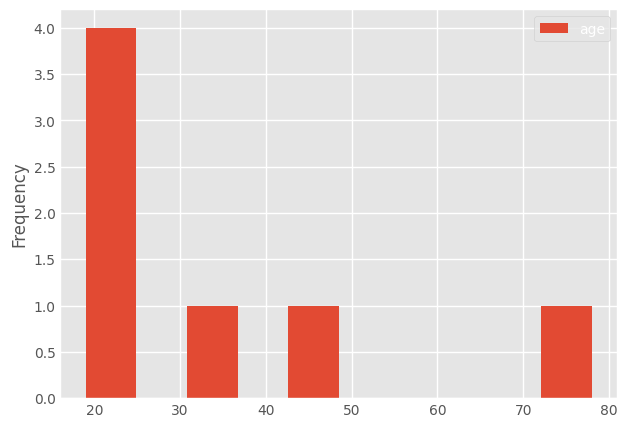

In [39]:
df[['age']].plot.hist()

<Axes: xlabel='num_children', ylabel='num_pets'>

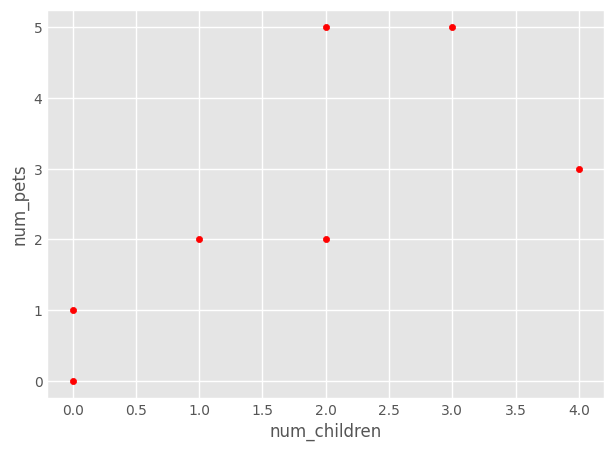

In [40]:

#Plot two dataframe columns as a scatter plot

# A scatter plot comparing num_children and num_pets
df.plot.scatter(x='num_children',y='num_pets',color='red')


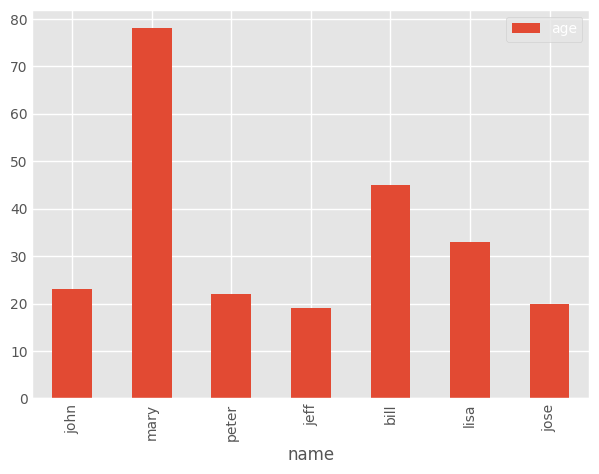

In [41]:
#Plot column values as a bar plot
df.plot.bar(x='name',y='age')
plt.show()

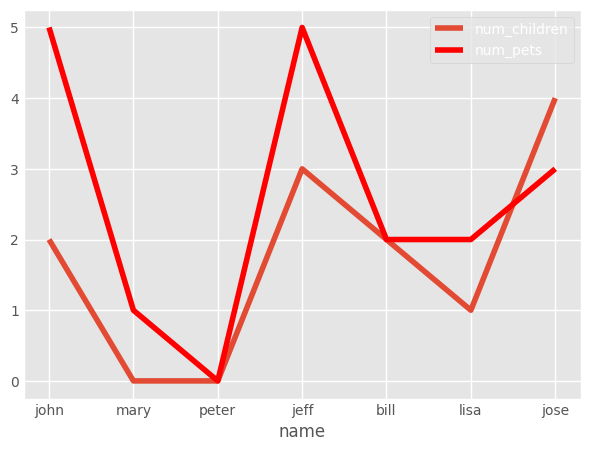

In [42]:
#Line plot with multiple columns
#Just reuse the Axes object.

# gca stands for 'get current axis'
ax = plt.gca()

df.plot.line(x='name',y='num_children',ax=ax)
df.plot.line(x='name',y='num_pets', color='red', ax=ax)
plt.show()

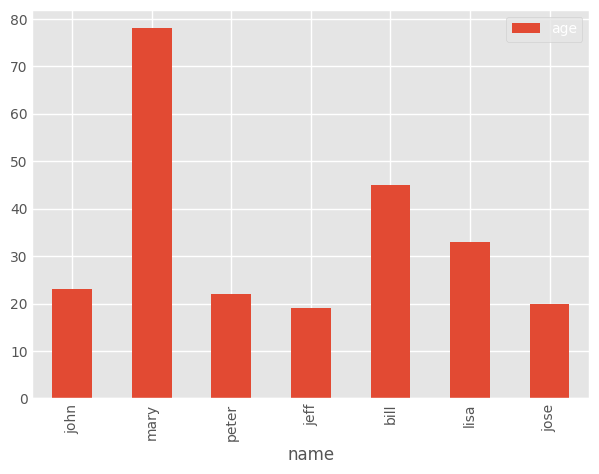

In [43]:
#Save plot to filePermalink
#Instead of calling plt.show(), call plt.savefig('outputfile.png'):

df.plot.bar(x='name',y='age')

# the plot gets saved to 'output.png'
plt.savefig('output.png')

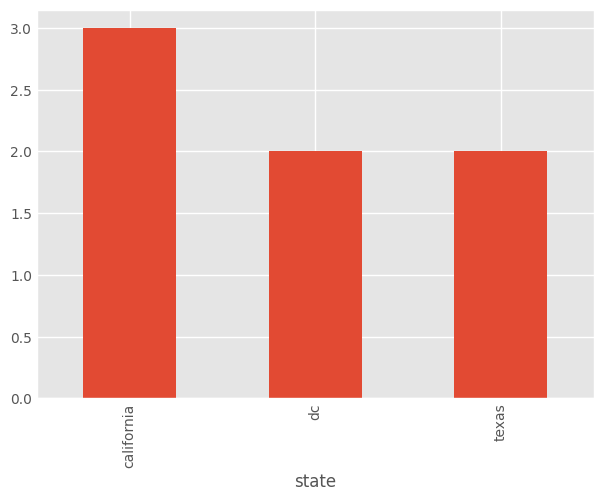

In [44]:
#Bar plot with group by
df.groupby('state')['name'].nunique().plot.bar()
plt.show()

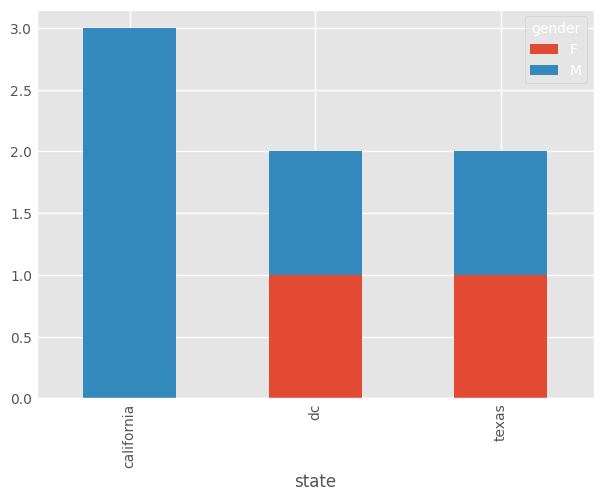

In [45]:
#Stacked bar plot with two-level group by
#Just do a normal groupby() and call unstack():

df.groupby(['state','gender']).size().unstack().plot.bar(stacked=True)
plt.show()

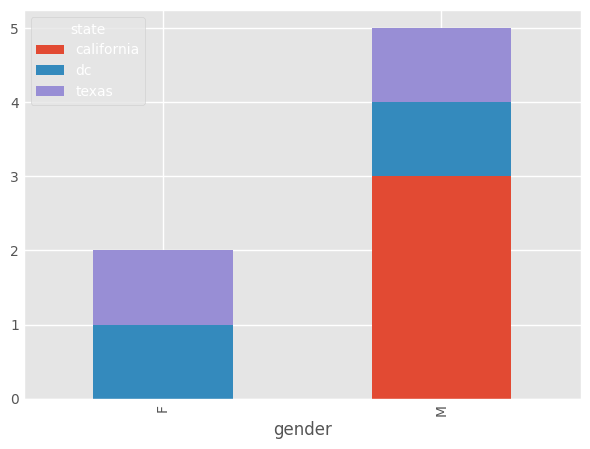

In [46]:
#count the people by gender, spliting by state:

df.groupby(['gender','state']).size().unstack().plot.bar(stacked=True)
plt.show()

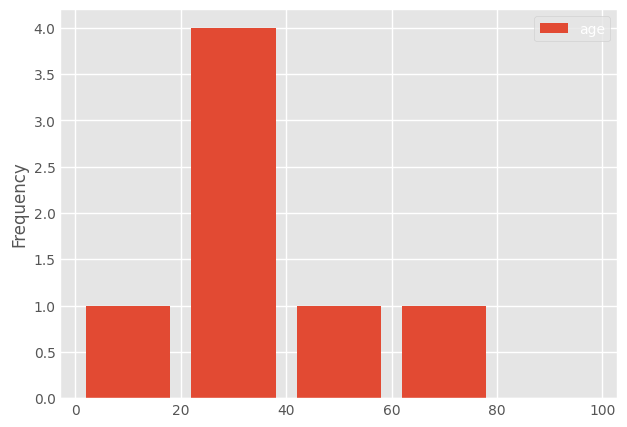

In [47]:
#Plot a histogram of column values

df[['age']].plot.hist(bins=[0,20,40,60,80,100],rwidth=0.8)
plt.show()

In [48]:
#Plot date histogram
#To plot the number of records per unit of time, you must first convert the date column to datetime using pandas.to_datetime().


df = pd.DataFrame({
    'name':[
        'john','lisa','peter','carl','linda','betty'
    ],
    'date_of_birth':[
        '01/21/1988','03/10/1977','07/25/1999','01/22/1977','09/30/1968','09/15/1970'
    ]
})
df

,name,date_of_birth
0,john,01/21/1988
1,lisa,03/10/1977
2,peter,07/25/1999
3,carl,01/22/1977
4,linda,09/30/1968
5,betty,09/15/1970


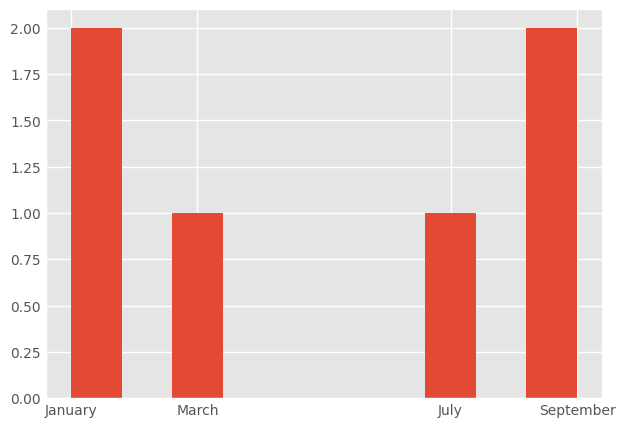

In [49]:
#Now convert the date column into datetime type and use plot(kind='hist'):
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])
#clear the current figure
plt.clf()
df_to_hist = df['date_of_birth'].map(lambda d: d.month)
ax = df_to_hist.hist()
ax.set_xticks(df_to_hist.unique())
ax.set_xticklabels(["January","March","July","September"])
plt.show()